# Lab 3 — Millions of TVs, Who Is Watching?
Name: Morozov Ivan | Group: KM-43

## Setup

In [14]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

In [ ]:
big5 = ["CBS", "NBC", "ABC", "FOX", "FNC"]
ten = big5 + ["FX", "BRAVO", "HGTV", "FOOD", "HIST"]

def bday(s):
    return (s - pd.Timedelta(hours=6)).dt.strftime("%Y-%m-%d")

def watched(df, t, id_col):
    d = df[(df.network_code == t.network_code) & (df.start_ts < t.end_ts) & (df.end_ts > t.start_ts)]
    ov = d.end_ts.clip(upper=t.end_ts) - d.start_ts.clip(lower=t.start_ts)
    ov = ov.groupby(d[id_col]).sum()
    return ov[ov >= pd.Timedelta(minutes=1)].index

acr = acr_sessions
acr["start_ts"] = acr.start_utc.dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["end_ts"] = acr.end_utc.dt.tz_convert("America/New_York").dt.tz_localize(None)
acr["day"] = bday(acr.start_ts)
acr["hours"] = (acr.end_ts - acr.start_ts).dt.total_seconds() / 3600
ok = acr[acr.end_ts - acr.start_ts >= pd.Timedelta(minutes=1)]
live = ok[ok.session_type == "live"]
intab = ok.groupby("day").tv_id.nunique()

daily_weights["day"] = daily_weights.broadcast_date.astype(str)
viewings["day"] = bday(viewings.start_ts)
viewings["hours"] = (viewings.end_ts - viewings.start_ts).dt.total_seconds() / 3600
hw = daily_weights[(daily_weights.resp_type == "H") & daily_weights.day.between("2024-10-14", "2024-10-27")]
hv = viewings[(viewings.resp_type == "H") & viewings.day.between("2024-10-14", "2024-10-27")]
w = hw.groupby("respondent_id").weight.mean()

## Task 1.1 — Five questions
**Answer:**

| Question | `acr_sessions` | Lab 1 `viewings` |
|---|---|---|
| **Grain** | one session on one TV (device, not a person) | one session of one person (R, L, S) or one household (H) on one network |
| **Key** | `session_id`; unit is `tv_id`, the map to homes goes only through `hashed_ip` | `viewing_id`; unit is `respondent_id`, and `respondent_id // 100` is the household |
| **Coverage** | 29,940 opted-in TVs, one per home, ~50 networks + apps + unknown, Oct 14-27 | about 3,900 households per day, ten networks, only `Live`, whole October 2024 |
| **Weight** | no weight, so every TV has weight 1 | daily weight, H sum to 125,800,000 and persons to 317,277,664 |
| **Provenance** | by-product of ACR on TVs where the owner agreed, a convenience sample (here simulated) | recruited panel, built to be representative (here simulated) |

**Biggest difference is provenance**, and absense of weight is a corollary of it. Nobody selected these homes by a known distribution, so we can't write down the inclusion probabilities. Grain is second: it is also a serious difference, but we can construct a map device -> people with a panel (see Bonus). For the unknown selection there is no such map without external data.

## Task 1.2 — Size and shape

In [3]:
print("TVs:", acr.tv_id.nunique())
print("Sessions:", len(acr))
print("Broadcast days:", acr.day.nunique())
print("Average TVs in-tab per day:", round(intab.mean(), 1))
print("Hours per TV per day, raw:", round(acr.hours.sum() / intab.sum(), 2))
print("Hours per TV per day, after edit rule:", f"{ok.hours.sum() / intab.sum():.2f}")
print("Share of sessions dropped:", round(1 - len(ok) / len(acr), 3))

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074.1
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.70
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [4]:
for c in ["session_type", "input_source"]:
    print((ok.groupby(c).hours.sum() / ok.hours.sum()).round(3), "\n")
unk = ok[ok.session_type == "unknown"].hours.sum() / ok.hours.sum()
print("Share of TV-on hours unknown (%):", round(100 * unk, 1))
print((ok[ok.session_type == "unknown"].groupby("input_source").hours.sum() / ok.groupby("input_source").hours.sum()).round(3))

session_type
app        0.257
dvr        0.025
live       0.322
unknown    0.396
Name: hours, dtype: float64 

input_source
antenna             0.086
built_in_app        0.307
cable_box           0.276
game_or_disc        0.024
satellite_box       0.076
streaming_device    0.231
Name: hours, dtype: float64 

Share of TV-on hours unknown (%): 39.6
input_source
antenna             0.362
built_in_app        0.066
cable_box           0.330
game_or_disc        1.000
satellite_box       0.328
streaming_device    0.889
Name: hours, dtype: float64


**Answer:** 39.6% of hours are `unknown`, and recognized live is only 32.2%. Also the edit rule removes 29.9% of sessions but almost no hours (4.74 -> 4.70), so the removed set has measure close to zero.

Real feed can have more unknown becouse the fingerprint library is a finite set and the real content is much bigger: local stations, foreign channels, old videos, etc. All what is outside of the library maps to `unknown`. Also some apps or inputs can block ACR. Our feed is simulated, so it's noise is bounded by the model.

Two kinds of viewing that go to `unknown`: **streaming through external device** (most of `streaming_device` hours are unknown) and **games or discs** (`game_or_disc` is 100% unknown, so `game_or_disc` is a subset of `unknown`).

## Task 2.1 — Match

In [5]:
n_ip = hh_attributes.hashed_ip.value_counts()
tvs = acr.drop_duplicates("tv_id")[["tv_id", "hashed_ip", "dma_code"]]
n = tvs.hashed_ip.map(n_ip).fillna(0)
print("Matched to one household (%):", round(100 * (n == 1).mean(), 1))
print("Shared IP, unresolved (%):", round(100 * (n > 1).mean(), 1))
print("Not matched (%):", round(100 * (n == 0).mean(), 1))
m = tvs[n == 1].merge(hh_attributes, on="hashed_ip")

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9


**Answer:** The relation IP -> household is not a function, and household -> IP is not injective. One IP can have several households (apartment building), and one household can change IP with time (dynamic address, VPN). So key is not unique and not stable. In our data 11.8% of TVs have shared IP and 22.9% have empty image, which implies that for 34.8% of TVs we know nothing about the home. Also, exactly one match is a necessary but not sufficient condition for a correct match.

## Task 2.2 — Profile

In [6]:
inc = {"Under $25k": "<50k", "$25k-$50k": "<50k", "$50k-$75k": "50-100k",
       "$75k-$100k": "50-100k", "$100k-$150k": "100k+", "$150k+": "100k+"}

def attr(group):
    a = viewer_attributes.merge(attributes[attributes.attr_group == group], on="attr_id")
    return a.set_index("respondent_id").attr_name

age = viewer_attributes[viewer_attributes.attr_id == 300].set_index("respondent_id").value
heads = viewer_attributes[viewer_attributes.attr_id.isin([701, 702])].sort_values("attr_id")
heads = heads.assign(hh=heads.respondent_id // 100 * 100).drop_duplicates("hh")
head_age = pd.cut(heads.set_index("hh").respondent_id.map(age), [0, 34, 49, 64, 200],
                  labels=["18-34", "35-49", "50-64", "65+"])

def profile(foot, panel):
    t = pd.DataFrame({"footprint": foot.value_counts(normalize=True),
                      "panel": w.groupby(panel.reindex(w.index), observed=True).sum() / w.sum()})
    t["index"] = (t.footprint / t.panel * 100).round(1)
    return t.round(3)

print(profile(m.region, attr("Census region")), "\n")
print(profile(m.income_band.map(inc), attr("Household income").map(inc)), "\n")
print(profile(m.head_age_band, head_age))

           footprint  panel  index
Midwest        0.201  0.210   96.0
Northeast      0.150  0.170   88.0
South          0.383  0.379  101.0
West           0.266  0.241  110.4 

         footprint  panel  index
100k+        0.421  0.350  120.1
50-100k      0.320  0.289  110.8
<50k         0.259  0.361   71.8 

       footprint  panel  index
18-34      0.196  0.190  103.6
35-49      0.348  0.303  115.0
50-64      0.263  0.240  109.6
65+        0.192  0.267   71.8


**Answer:** Over-represented: income $100k+ (120.1), $50-100k (110.8) and West (110.4). Under-represented: under $50k (71.8, the biggest deviation) and Northeast (88.0). South and Midwest are in a small neighbourhood of 100. I checked age of the head also: 65+ has index 71.8 and 35-49 has 115.0.

Possible reason: to be in this set, the home must buy a new smart TV, connect it to internet and accept the terms. It is an intersection of three conditions, and each of them correlates with income and (negatively) with age. Note that the profile is defined only on the matched subset (65.2%), and income is modeled, so some part of the skew can be an error of the vendor.

## Task 2.3 — Ratings

In [7]:
tele = reference_ratings.merge(programs, on="telecast_id")
tele["day"] = tele.broadcast_date.astype(str)
tele["tv_rating"] = [100 * len(watched(live, t, "tv_id")) / intab[t.day] for t in tele.itertuples()]
tele["ratio"] = tele.tv_rating / tele.hh_rating
print(tele[["program_name", "network_code", "tv_rating", "hh_rating", "ratio"]].sort_values("ratio")
      .round({"tv_rating": 1, "hh_rating": 1, "ratio": 3}).to_string(index=False))

                        program_name network_code  tv_rating  hh_rating  ratio
                             Hannity          FNC        0.8        2.3  0.359
                                NCIS          CBS        5.4       10.6  0.509
                   Unsellable Houses         HGTV        2.1        3.7  0.568
The Real Housewives of New York City        BRAVO        0.7        1.2  0.600
       Halloween Baking Championship         FOOD        1.0        1.6  0.604
                      MLB Postseason          FOX       16.5       25.9  0.639
                        Grotesquerie           FX        2.3        3.5  0.641
                        NFL Football          NBC       21.2       33.1  0.641


**Answer:** All TV ratings are too low, the ratio is in the interval [0.359, 0.641]. So there is a common factor (only one TV from the home and unknown sessions), and it would be almost a constant multiplier if the footprint was representative. But the ratio is not constant, so there is a second component which depends on the audience.

Furthest: *Hannity* (0.359) and *NCIS* (0.509). Closest: Sunday Night Football (0.641), *Grotesquerie* (0.641) and World Series (0.639). In absolute points the order is different, SNF has the biggest gap (-11.9), because its rating is big.

The pattern fits the profile: 65+ homes have index 71.8, Fox News and CBS are older, which implies the lowest ratings there. FX is younger and it is on the top. Bravo (0.600) is a small counterexample, it is young too but stay near the median. Its sampling error is about +-0.04 in ratio, so I would not make a strong conclusion from it. Age and income are probably not orthogonal, so I can't decompose the skew into two independant parts.

## Task 3.1 — Hours per home

In [8]:
l10 = live[live.network_code.isin(ten)]
tv_h = l10.hours.sum() / intab.sum()
panel_h = (hv.hours * hv.weight).sum() / hw.weight.sum()
print("Live hours per TV per day (ten networks):", round(tv_h, 2))
print("Live hours per panel household per day (ten networks):", round(panel_h, 2))
print("ratio", round(tv_h / panel_h, 3))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
ratio 0.452


**Answer:** TVs are lower: 0.87 vs 1.92, it is 55% less. The domains are diffrent: H row is a union over all TV sets of the home, and the feed is only one element of this union. If the viewing was uniform over 2.6 sets, we would expect 1/2.6 ~ 0.38 (or 1.1/2.6 ~ 0.42 with sets of same brand). We have 0.45, wich is higher, so probably smart TV is the main set and distribution is not uniform. Two other terms also decrease the value: live viewing that became `unknown`, and lack of 65+ homes. I can't separate these terms with this data.

## Task 3.2 — Network shares

In [9]:
hh_hours = (hv.hours * hv.weight).groupby(hv.network_code).sum()
sh = pd.DataFrame({"TVs": l10.groupby("network_code").hours.sum() / l10.hours.sum(),
                   "panel": hh_hours / hh_hours.sum()})
sh["ratio"] = sh.TVs / sh.panel
print(sh.sort_values("ratio").round(3))

                TVs  panel  ratio
network_code                     
FNC           0.085  0.110  0.774
CBS           0.182  0.196  0.928
NBC           0.214  0.206  1.036
HIST          0.019  0.019  1.036
FOX           0.201  0.194  1.039
ABC           0.196  0.187  1.048
FOOD          0.024  0.022  1.089
HGTV          0.034  0.031  1.104
BRAVO         0.016  0.013  1.220
FX            0.028  0.022  1.291


**Answer:** Under-stated: Fox News (0.085 vs 0.110) and CBS (0.182 vs 0.196). Over-stated: FX (ratio 1.291), Bravo (1.220), and less HGTV and Food. ABC, NBC, FOX and History are equal to panel up to eps ~ 5%. It is consistent with 2.3: older networks loose share, younger ones gain. Shares sum to 1, so if one goes down then some other must go up.

## Task 3.3 — What each can see
**Answer:**

Panel \ TVs (panel sees, TVs not):
- people: age, sex, guests, so who exactly is watching;
- all TV sets in the home;
- homes without opted-in smart TV, plus weights to project on whole US.

TVs \ Panel (TVs see, ten-network files not):
- other networks (ESPN, PBS, MSNBC, Univision...);
- apps (25.7% of hours), DVR and total TV-on time;
- input source, market (DMA) and exact seconds, with n almost 8 times bigger.

## Task 4.1 — Daily plots

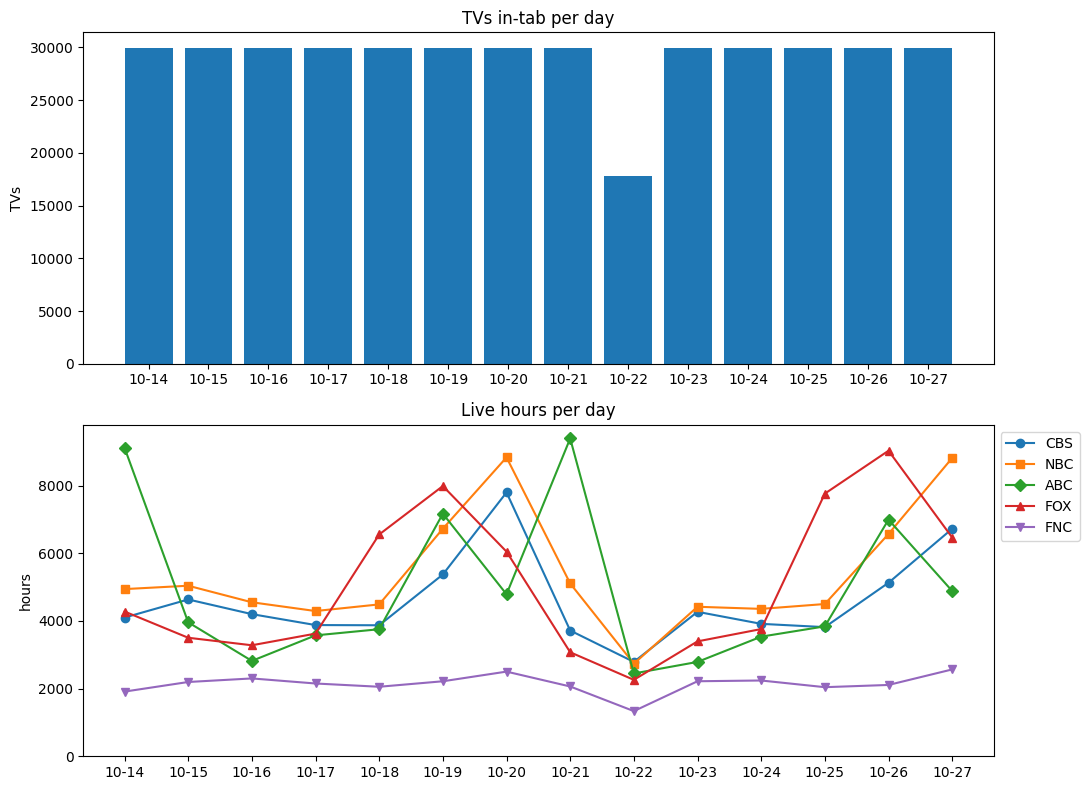

            intab  hours_per_tv
day                            
2024-10-14  29940          4.52
2024-10-15  29940          4.46
2024-10-16  29940          4.45
2024-10-17  29940          4.41
2024-10-18  29940          4.39
2024-10-19  29940          5.31
2024-10-20  29940          5.32
2024-10-21  29940          4.56
2024-10-22  17818          4.45
2024-10-23  29940          4.44
2024-10-24  29940          4.43
2024-10-25  29940          4.41
2024-10-26  29940          5.28
2024-10-27  29940          5.30


In [10]:
d5 = live[live.network_code.isin(big5)].pivot_table(index="day", columns="network_code", values="hours", aggfunc="sum")[big5]
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
ax[0].bar(intab.index.str[5:], intab)
ax[0].set_title("TVs in-tab per day")
ax[0].set_ylabel("TVs")
for net, mark in zip(big5, "osD^v"):
    ax[1].plot(d5.index.str[5:], d5[net], marker=mark, label=net)
ax[1].set_title("Live hours per day")
ax[1].set_ylabel("hours")
ax[1].set_ylim(0)
ax[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()
print(pd.DataFrame({"intab": intab, "hours_per_tv": (ok.groupby("day").hours.sum() / intab).round(2)}))

## Task 4.2 — Spike and broken day

In [11]:
day, net = live.groupby(["day", "network_code"]).hours.sum().idxmax()
bad = intab.idxmin()
print("Biggest spike (date, network):", day, net)
print("Broken day (date):", bad)
print(programs[(programs.network_code == net) & (programs.broadcast_date.astype(str) == day)
               & (programs.program_type == "sports")][["program_name", "episode_name", "start_ts", "end_ts"]])
lost = ~tvs.tv_id.isin(ok[ok.day == bad].tv_id)
print("lost TVs:", lost.sum())
by_dma = lost.groupby(tvs.dma_code).mean()
print("lost share by DMA, min and max:", round(by_dma.min(), 3), round(by_dma.max(), 3))

Biggest spike (date, network): 2024-10-21 ABC
Broken day (date): 2024-10-22
     program_name            episode_name            start_ts  \
282  NFL Football  NFL Football: BAL @ TB 2024-10-21 20:15:00   

                 end_ts  
282 2024-10-21 23:25:00  
lost TVs: 12122
lost share by DMA, min and max: 0.37 0.443


**Answer:** The global maximum is ABC on 2024-10-21. There was NFL Football (Monday Night Football, BAL @ TB, 20:15-23:25). Previous Monday (BUF @ NYJ) is almost the same maximum, so the process is kind of periodic with period 7 days.

Broken day is 2024-10-22. In-tab falls from 29,940 to 17,818 (12,122 TVs lost, 40%), but hours per in-tab TV are invariant (4.45, like other weekdays). It implies that behaviour of the audience did not change, only the denominator did. In every DMA 37-44% of TVs are lost, so it looks like almost uniform random loss, for example part of the data were not delivered.

If nobody noticed: all daily totals are about 40% lower, and it looks like a fall of audience on all networks at once. The rating stays almost the same, because numerator and denominator are multiplied by the same factor, but only if we divide by in-tab of that day. With 29,940 in the denominator it would be 40% too low. SE also grows by sqrt(29940/17818) ~ 1.3.

I would **flag** it. Ratings can be used with true denominator, totals should not be compared with other days (or should be normalized by in-tab). If vendor can resend the data then fix.

## Task 5.1 — Sampling error vs bias

In [12]:
s = tele[tele.program_name.isin(["NFL Football", "Hannity", "Unsellable Houses"])][["program_name", "day", "tv_rating", "hh_rating"]].copy()
p = s.hh_rating / 100
s["SE footprint"] = 100 * (p * (1 - p) / s.day.map(intab)) ** 0.5
s["SE panel"] = 100 * (p * (1 - p) / s.day.map(hw.groupby("day").size())) ** 0.5
s["TVs - reference"] = s.tv_rating - s.hh_rating
print(s.round({"tv_rating": 1, "hh_rating": 1, "SE footprint": 2, "SE panel": 2, "TVs - reference": 1}).to_string(index=False))
print("SE panel / SE footprint:", (s["SE panel"] / s["SE footprint"]).round(2).tolist())

     program_name        day  tv_rating  hh_rating  SE footprint  SE panel  TVs - reference
     NFL Football 2024-10-27       21.2       33.1          0.27      0.75            -11.9
          Hannity 2024-10-16        0.8        2.3          0.09      0.24             -1.5
Unsellable Houses 2024-10-16        2.1        3.7          0.11      0.30             -1.6
SE panel / SE footprint: [2.77, 2.78, 2.78]


**Answer:** SE of the footprint is about 2.8 times smaller (sqrt(29940/3900)): 0.27 vs 0.75 for SNF, 0.09 vs 0.24 for *Hannity*, 0.11 vs 0.30 for *Unsellable Houses*. But the gaps are -11.9, -1.5 and -1.6 points, which is about 44, 17 and 15 SE. So bias strictly dominates the sampling error.

More data does not help here: SE is O(1/sqrt(n)) and goes to 0, but bias does not depend on n. The estimator converges, but to the wrong limit, in other words it is not consistent. A big sample does not imply a representative sample.

## Task 5.2 — Answer to the planner
**Answer:** For the presentation tomorrow I recommend to use the currency rating, 33.1, and name the currency as the source. From this feed I can only say that 21.2% of the in-tab TVs watched the game, and it is not an estimate of the US household rating, because it is biased down by 36% and this is not sampling noise (SE is only 0.3). The feed does not see people, other sets in the home, and the content which was not recognized (39.6% of hours are unknown); for apps it knows that the app is on, but not what is watched. It also doesn't include homes that opted out, and only 65.2% of TVs match exactly one household, so homes with low income and older heads are under-represented. Before planning I would need weights (at least by age, income and region), a correction for the other sets, and viewers per household from a panel. Then I would need to verify it on other telecasts with known currency ratings. Until then, the feed is fine only for relative comparisons, with in-tab checked every day.

## Bonus

In [13]:
t = tele[tele.program_name == "NFL Football"].iloc[0]
dw = daily_weights[daily_weights.day == t.day]
h = dw[dw.resp_type == "H"]
a = dw[dw.resp_type.isin(["R", "L"]) & dw.respondent_id.map(age).between(25, 54)]
v = watched(viewings, t, "respondent_id")
a_w = a[a.respondent_id.isin(v)].weight.sum()
vpvh = a_w / h[h.respondent_id.isin(v)].weight.sum()
print("VPVH A25-54:", round(vpvh, 3))
print("A25-54 rating (persons):", round(t.tv_rating * vpvh * h.weight.sum() / a.weight.sum(), 1))
print("panel A25-54 rating:", round(100 * a_w / a.weight.sum(), 1))

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
panel A25-54 rating: 17.8


**Answer:** We get 11.1, but the panel itself gives 17.8, so the bias of the household rating propagates linearly to the persons rating. Assumption: VPVH is invariant, so homes of the footprint which watched the game have the same number of A25-54 viewers as the panel homes. It is not obvious, because footprint is richer and have less 65+ homes. Also we assume that household rating from TVs is correct, and this is false (2.3). VPVH is only a map from households to people, it doesn't remove the bias.